In [ ]:
# Eastern Freight Logistics
## Operational Performance Root-Cause Analysis

### Objective
Identify and quantify the drivers of declining
On-Time Delivery performance across 12 hubs.

### Tools
Python, Pandas, NumPy, SciPy, Statsmodels,
Matplotlib and Seaborn.

In [1]:
# Install required libraries

!pip install pandas numpy scipy statsmodels matplotlib seaborn pyarrow

In [2]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

from datetime import datetime

import warnings
warnings.filterwarnings("ignore")

# Display settings

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Reproducibility

np.random.seed(42)

print("Environment setup successful!")

Environment setup successful!


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Eastern_Freight_Project"

# Check whether our project folder exists

if os.path.exists(PROJECT_DIR):
    print("Project folder found successfully!")

    print("\nProject folders:")

    for folder in os.listdir(PROJECT_DIR):
        print("-", folder)

else:
    print("Project folder not found.")
    print("Please check where you extracted the ZIP.")

Project folder not found.
Please check where you extracted the ZIP.


In [6]:
import os

print("Folders inside MyDrive:\n")

for item in os.listdir('/content/drive/MyDrive'):
    print(item)

Folders inside MyDrive:

Colab Notebooks
majoor project.gdoc
Google Earth
Untitled spreadsheet (3).gsheet
Untitled spreadsheet (2).gsheet
Untitled spreadsheet (1).gsheet
Untitled spreadsheet.gsheet
Google AI Studio (1)
Google AI Studio
AI content Lumen AI 7 sem Lakshya.mp4


In [7]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Eastern_Freight_Project"

print(os.path.exists(PROJECT_DIR))

True


In [8]:
import os
import pandas as pd
import numpy as np

# Define project directories

RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")
CLEAN_DIR = os.path.join(PROJECT_DIR, "data", "cleaned")

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(CLEAN_DIR, exist_ok=True)

# Define 12 logistics hubs

hub_data = {
    "hub_id": [
        "H01", "H02", "H03", "H04",
        "H05", "H06", "H07", "H08",
        "H09", "H10", "H11", "H12"
    ],

    "old_hub_name": [
        "Kolkata Central",
        "Howrah Depot",
        "Durgapur Old",
        "Asansol Depot",
        "Siliguri Old",
        "Bhubaneswar Depot",
        "Patna Central",
        "Ranchi Depot",
        "Guwahati Old",
        "Jamshedpur Depot",
        "Varanasi Central",
        "Lucknow Old"
    ],

    "canonical_hub_name": [
        "Kolkata Main",
        "Howrah Hub",
        "Durgapur Hub",
        "Asansol Hub",
        "Siliguri Hub",
        "Bhubaneswar Hub",
        "Patna Hub",
        "Ranchi Hub",
        "Guwahati Hub",
        "Jamshedpur Hub",
        "Varanasi Hub",
        "Lucknow Hub"
    ]
}

hub_mapping = pd.DataFrame(hub_data)

hub_mapping["effective_date"] = "2025-07-01"

# Save the dataset

hub_mapping.to_csv(
    os.path.join(RAW_DIR, "hub_mapping.csv"),
    index=False
)

print("Hub mapping created successfully!")

display(hub_mapping)

Hub mapping created successfully!


,hub_id,old_hub_name,canonical_hub_name,effective_date
0,H01,Kolkata Central,Kolkata Main,2025-07-01
1,H02,Howrah Depot,Howrah Hub,2025-07-01
2,H03,Durgapur Old,Durgapur Hub,2025-07-01
3,H04,Asansol Depot,Asansol Hub,2025-07-01
4,H05,Siliguri Old,Siliguri Hub,2025-07-01
5,H06,Bhubaneswar Depot,Bhubaneswar Hub,2025-07-01
6,H07,Patna Central,Patna Hub,2025-07-01
7,H08,Ranchi Depot,Ranchi Hub,2025-07-01
8,H09,Guwahati Old,Guwahati Hub,2025-07-01
9,H10,Jamshedpur Depot,Jamshedpur Hub,2025-07-01


In [9]:
# Load our hub mapping

hub_mapping = pd.read_csv(
    os.path.join(RAW_DIR, "hub_mapping.csv")
)

# Set random generator

rng = np.random.default_rng(42)

# Number of test shipments

n = 10000

# Generate dates across 2025
# October and November have festive-season peaks

days = pd.date_range("2025-01-01", "2025-12-31")

weights = np.ones(len(days))

festive = (
    (days.month == 10) |
    (days.month == 11)
)

weights[festive] = 1.6
weights = weights / weights.sum()

selected_days = rng.choice(
    days.to_numpy(),
    size=n,
    p=weights
)

dispatch = (
    pd.to_datetime(selected_days) +
    pd.to_timedelta(
        rng.integers(0, 1440, n),
        unit="m"
    )
)

# Assign hubs

hub_index = rng.integers(0, 12, n)

hub_ids = hub_mapping["hub_id"].to_numpy()[hub_index]

# Identify network change date

post_change = (
    dispatch >= pd.Timestamp("2025-07-01")
)

# Warehouse dwell time

affected_hubs = ["H01", "H02", "H05"]

warehouse_dwell = (
    np.maximum(1, rng.normal(5, 1.2, n))
    +
    np.where(
        post_change & np.isin(hub_ids, affected_hubs),
        7,
        0
    )
)

# Vehicle breakdowns

breakdown_probability = np.where(
    post_change,
    0.06,
    0.02
)

breakdown_flag = rng.binomial(
    1,
    breakdown_probability
)

# Route details

distance = np.clip(
    rng.gamma(2, 75, n),
    30,
    700
)

planned_transit = 4 + distance / 45
inbound_transit = 2 + distance / 100

road_delay = rng.normal(0, 5, n)

actual_transit = np.maximum(
    1,
    planned_transit + road_delay + breakdown_flag * 8
)

# Calculate delivery timestamps

promised_delivery = (
    dispatch +
    pd.to_timedelta(
        inbound_transit + planned_transit + 12,
        unit="h"
    )
)

actual_delivery = (
    dispatch +
    pd.to_timedelta(
        inbound_transit + warehouse_dwell + actual_transit,
        unit="h"
    )
)

# Create preview dataset

pilot = pd.DataFrame({
    "shipment_id": np.arange(1, n + 1),
    "hub_id": hub_ids,
    "dispatch_date": dispatch,
    "distance_km": distance,
    "warehouse_dwell_hours": warehouse_dwell,
    "breakdown_flag": breakdown_flag,
    "promised_delivery": promised_delivery,
    "actual_delivery": actual_delivery
})

pilot["delivery_delay_hours"] = (
    pilot["actual_delivery"] -
    pilot["promised_delivery"]
).dt.total_seconds() / 3600

pilot["on_time"] = (
    pilot["delivery_delay_hours"] <= 0
)

pilot["quarter"] = (
    pilot["dispatch_date"].dt.quarter
)

# Save preview

pilot.to_csv(
    os.path.join(RAW_DIR, "pilot_shipments_preview.csv"),
    index=False
)

print("Pilot dataset generated!")
print("Total shipments:", len(pilot))

display(pilot.head(10))

Pilot dataset generated!
Total shipments: 10000


,shipment_id,hub_id,dispatch_date,distance_km,warehouse_dwell_hours,breakdown_flag,promised_delivery,actual_delivery,delivery_delay_hours,on_time,quarter
0,1,H03,2025-10-24 00:49:00,270.943251,2.809073,0,2025-10-25 03:32:49.417088473,2025-10-24 23:59:14.868805490,-3.559597,True,4
1,2,H05,2025-06-26 17:17:00,108.687879,4.526374,0,2025-06-27 14:47:07.793965735,2025-06-27 01:53:47.709826650,-12.888912,True,2
2,3,H11,2025-11-14 05:08:00,30.000000,2.901919,0,2025-11-15 00:06:00.000000001,2025-11-14 11:20:06.907972622,-12.764748,True,4
3,4,H02,2025-10-05 17:04:00,141.890350,14.449847,0,2025-10-06 15:38:19.280633073,2025-10-06 12:21:31.364746641,-3.279977,True,4
4,5,H02,2025-02-07 13:32:00,35.532857,5.254989,0,2025-02-08 08:40:41.811444294,2025-02-08 05:44:41.992574781,-2.933283,True,1
5,6,H04,2025-12-22 04:51:00,298.963709,5.150995,0,2025-12-23 08:28:59.790232394,2025-12-23 05:44:14.852306540,-2.745816,True,4
6,7,H08,2025-10-21 11:16:00,230.305074,5.278488,0,2025-10-22 12:41:15.388580107,2025-10-22 08:10:39.246307725,-4.510040,True,4
7,8,H10,2025-10-27 00:52:00,52.268875,5.725425,0,2025-10-27 20:33:03.189503475,2025-10-27 19:49:48.319435008,-0.720797,True,4
8,9,H07,2025-02-21 16:50:00,393.477614,6.173786,0,2025-02-22 23:30:43.403243703,2025-02-22 16:46:40.491678127,-6.734142,True,1
9,10,H06,2025-06-30 07:17:00,74.818476,3.123735,0,2025-07-01 03:41:38.943213022,2025-06-30 17:27:47.260089008,-10.231023,True,2


In [10]:
print("Overall On-Time Delivery:")

print(
    round(pilot["on_time"].mean() * 100, 2),
    "%"
)

print("\nShipments by quarter:")

print(
    pilot["quarter"].value_counts().sort_index()
)

print("\nAverage warehouse dwell time:")

print(
    round(
        pilot["warehouse_dwell_hours"].mean(),
        2
    ),
    "hours"
)

print("\nBreakdown rate:")

print(
    round(
        pilot["breakdown_flag"].mean() * 100,
        2
    ),
    "%"
)

Overall On-Time Delivery:
83.55 %

Shipments by quarter:
quarter
1    2277
2    2273
3    2307
4    3143
Name: count, dtype: int64

Average warehouse dwell time:
5.97 hours

Breakdown rate:
4.24 %


In [11]:
# Quarterly delivery performance

quarterly_performance = (
    pilot.groupby("quarter")
    .agg(
        total_shipments=("shipment_id", "count"),
        on_time_rate=("on_time", "mean"),
        avg_delay=("delivery_delay_hours", "mean"),
        avg_warehouse_dwell=("warehouse_dwell_hours", "mean"),
        breakdown_rate=("breakdown_flag", "mean")
    )
    .reset_index()
)

quarterly_performance["on_time_rate"] *= 100
quarterly_performance["breakdown_rate"] *= 100

display(quarterly_performance.round(2))

,quarter,total_shipments,on_time_rate,avg_delay,avg_warehouse_dwell,breakdown_rate
0,1,2277,91.26,-6.67,5.01,1.93
1,2,2273,90.32,-6.57,5.04,1.50
2,3,2307,77.85,-4.29,6.72,6.85
3,4,3143,77.25,-4.34,6.78,5.98


In [12]:
# Hub-level performance

hub_performance = (
    pilot.groupby("hub_id")
    .agg(
        shipments=("shipment_id", "count"),
        OTD=("on_time", "mean"),
        avg_delay=("delivery_delay_hours", "mean"),
        avg_warehouse_dwell=("warehouse_dwell_hours", "mean"),
        breakdown_rate=("breakdown_flag", "mean")
    )
    .reset_index()
)

hub_performance["OTD"] *= 100
hub_performance["breakdown_rate"] *= 100

display(
    hub_performance.sort_values(
        "OTD"
    ).round(2)
)

,hub_id,shipments,OTD,avg_delay,avg_warehouse_dwell,breakdown_rate
4,H05,769,65.54,-2.27,8.76,4.55
0,H01,869,65.59,-2.40,8.81,3.45
1,H02,840,65.95,-2.55,8.91,4.05
8,H09,850,87.06,-5.82,5.10,4.94
10,H11,790,88.48,-6.31,5.02,4.30
6,H07,822,88.93,-6.51,4.97,3.89
9,H10,834,88.97,-6.39,5.05,5.28
11,H12,877,89.40,-6.17,5.01,3.76
5,H06,814,89.43,-6.47,4.99,3.56
3,H04,847,90.32,-6.43,5.03,3.66


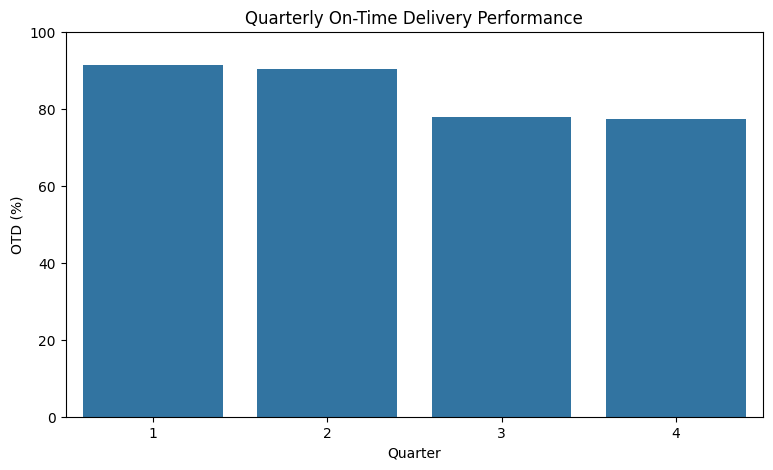

In [13]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=quarterly_performance,
    x="quarter",
    y="on_time_rate"
)

plt.title("Quarterly On-Time Delivery Performance")
plt.xlabel("Quarter")
plt.ylabel("OTD (%)")

plt.ylim(0, 100)
plt.show()

In [14]:
# Identify the three hubs we want to investigate
affected_hubs = ["H01", "H02", "H05"]

# Label each shipment by hub group
pilot["hub_group"] = np.where(
    pilot["hub_id"].isin(affected_hubs),
    "Affected hubs",
    "Other hubs"
)

# Split the year into two periods
pilot["period"] = np.where(
    pilot["dispatch_date"] < "2025-07-01",
    "Before July",
    "From July onward"
)

# Compare delivery performance across both dimensions
comparison = (
    pilot.groupby(["hub_group", "period"])
    .agg(
        shipments=("shipment_id", "count"),
        OTD=("on_time", "mean"),
        avg_dwell=("warehouse_dwell_hours", "mean"),
        breakdown_rate=("breakdown_flag", "mean")
    )
    .reset_index()
)

# Convert rates into percentages
comparison["OTD"] *= 100
comparison["breakdown_rate"] *= 100

display(comparison.round(2))

,hub_group,period,shipments,OTD,avg_dwell,breakdown_rate
0,Affected hubs,Before July,1137,90.85,5.03,1.58
1,Affected hubs,From July onward,1341,44.37,12.05,6.04
2,Other hubs,Before July,3413,90.77,5.02,1.76
3,Other hubs,From July onward,4109,88.32,5.03,6.45


In [15]:
from scipy.stats import chi2_contingency

# Keep only shipments from the three affected hubs
affected = pilot[pilot["hub_group"] == "Affected hubs"]

# Compare before July with July onward
table = pd.crosstab(
    affected["period"],
    affected["on_time"]
)

print("On-time delivery counts:")
display(table)

# Run the chi-square test
chi2, p_value, dof, expected = chi2_contingency(table)

print("Chi-square statistic:", round(chi2, 2))
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference.")

On-time delivery counts:


on_time,False,True
period,,
Before July,104,1033
From July onward,746,595


Chi-square statistic: 587.88
P-value: 7.236641318830558e-130
Result: Statistically significant difference.


In [16]:
from scipy.stats import ttest_ind

# Select shipments from affected hubs
affected = pilot[pilot["hub_group"] == "Affected hubs"]

# Separate warehouse dwell times by period
before = affected.loc[
    affected["period"] == "Before July",
    "warehouse_dwell_hours"
]

after = affected.loc[
    affected["period"] == "From July onward",
    "warehouse_dwell_hours"
]

# Run Welch's t-test
t_stat, p_value = ttest_ind(
    before,
    after,
    equal_var=False
)

print("Average dwell before July:", round(before.mean(), 2))
print("Average dwell after July:", round(after.mean(), 2))
print("Increase in dwell hours:", round(after.mean() - before.mean(), 2))
print("T-statistic:", round(t_stat, 2))
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Significant increase in warehouse dwell time.")
else:
    print("Result: No statistically significant increase detected.")


Average dwell before July: 5.03
Average dwell after July: 12.05
Increase in dwell hours: 7.02
T-statistic: -146.56
P-value: 0.0
Result: Significant increase in warehouse dwell time.


In [17]:
from scipy.stats import ttest_ind

results = []

for hub in ["H01", "H02", "H05"]:

    hub_data = pilot[pilot["hub_id"] == hub]

    before = hub_data.loc[
        hub_data["period"] == "Before July",
        "warehouse_dwell_hours"
    ]

    after = hub_data.loc[
        hub_data["period"] == "From July onward",
        "warehouse_dwell_hours"
    ]

    t_stat, p_value = ttest_ind(
        before,
        after,
        equal_var=False
    )

    results.append({
        "hub_id": hub,
        "dwell_before": before.mean(),
        "dwell_after": after.mean(),
        "increase_hours": after.mean() - before.mean(),
        "p_value": p_value
    })

hub_dwell_test = pd.DataFrame(results)

display(hub_dwell_test.round(4))

,hub_id,dwell_before,dwell_after,increase_hours,p_value
0,H01,4.9759,11.9992,7.0234,0.0
1,H02,5.0772,12.0435,6.9663,0.0
2,H05,5.0386,12.1026,7.0639,0.0


In [18]:
# Compare on-time delivery for shipments
# with and without vehicle breakdowns

breakdown_comparison = (
    pilot.groupby("breakdown_flag")
    .agg(
        shipments=("shipment_id", "count"),
        OTD=("on_time", "mean"),
        avg_delay=("delivery_delay_hours", "mean")
    )
    .reset_index()
)

breakdown_comparison["OTD"] *= 100

breakdown_comparison["breakdown_flag"] = (
    breakdown_comparison["breakdown_flag"]
    .map({0: "No breakdown", 1: "Breakdown"})
)

display(breakdown_comparison.round(2))

,breakdown_flag,shipments,OTD,avg_delay
0,No breakdown,9576,85.63,-5.71
1,Breakdown,424,36.56,2.44


In [19]:
from scipy.stats import chi2_contingency

# Count on-time and late deliveries by breakdown status
breakdown_table = pd.crosstab(
    pilot["breakdown_flag"],
    pilot["on_time"]
)

print("Breakdown vs delivery outcome:")
display(breakdown_table)

# Run the chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    breakdown_table
)

print("Chi-square statistic:", round(chi2, 2))
print("P-value:", p_value)

if p_value < 0.05:
    print("Result: Significant association between breakdowns and OTD.")
else:
    print("Result: No statistically significant association detected.")

Breakdown vs delivery outcome:


on_time,False,True
breakdown_flag,,
0,1376,8200
1,269,155


Chi-square statistic: 707.88
P-value: 5.778266550321827e-156
Result: Significant association between breakdowns and OTD.


In [20]:
# Calculate breakdown rates for all 12 hubs

hub_breakdowns = (
    pilot.groupby("hub_id")
    .agg(
        shipments=("shipment_id", "count"),
        breakdowns=("breakdown_flag", "sum"),
        OTD=("on_time", "mean")
    )
    .reset_index()
)

hub_breakdowns["breakdown_rate"] = (
    hub_breakdowns["breakdowns"]
    / hub_breakdowns["shipments"] * 100
)

hub_breakdowns["OTD"] *= 100

display(
    hub_breakdowns.sort_values(
        "breakdown_rate",
        ascending=False
    ).round(2)
)

,hub_id,shipments,breakdowns,OTD,breakdown_rate
9,H10,834,44,88.97,5.28
8,H09,850,42,87.06,4.94
7,H08,855,42,91.11,4.91
2,H03,833,38,91.12,4.56
4,H05,769,35,65.54,4.55
10,H11,790,34,88.48,4.30
1,H02,840,34,65.95,4.05
6,H07,822,32,88.93,3.89
11,H12,877,33,89.40,3.76
3,H04,847,31,90.32,3.66


In [21]:
breakdown_trend = (
    pilot.groupby(["hub_group", "period"])
    .agg(
        shipments=("shipment_id", "count"),
        breakdowns=("breakdown_flag", "sum")
    )
    .reset_index()
)

breakdown_trend["breakdown_rate"] = (
    breakdown_trend["breakdowns"]
    / breakdown_trend["shipments"] * 100
)

display(breakdown_trend.round(2))

,hub_group,period,shipments,breakdowns,breakdown_rate
0,Affected hubs,Before July,1137,18,1.58
1,Affected hubs,From July onward,1341,81,6.04
2,Other hubs,Before July,3413,60,1.76
3,Other hubs,From July onward,4109,265,6.45


In [22]:
import statsmodels.formula.api as smf
import numpy as np

# Create a binary indicator for affected hubs
pilot["affected_hub"] = (
    pilot["hub_id"].isin(["H01", "H02", "H05"])
).astype(int)

# Create a binary indicator for the period after July
pilot["post_july"] = (
    pilot["dispatch_date"] >= "2025-07-01"
).astype(int)

# Fit logistic regression
model = smf.logit(
    formula="""
    on_time ~ warehouse_dwell_hours
    + breakdown_flag
    + distance
    + affected_hub
    + post_july
    + affected_hub:post_july
    """,
    data=pilot
).fit()

print(model.summary())

ValueError: endog has evaluated to an array with multiple columns that has shape (10000, 2). This occurs when the variable converted to endog is non-numeric (e.g., bool or str).

In [23]:
import statsmodels.formula.api as smf
import numpy as np

# Create a binary indicator for affected hubs
pilot["affected_hub"] = (
    pilot["hub_id"].isin(["H01", "H02", "H05"])
).astype(int)

# Create a binary indicator for the period after July
pilot["post_july"] = (
    pilot["dispatch_date"] >= "2025-07-01"
).astype(int)

# Fit logistic regression
model = smf.logit(
    formula="""
    on_time ~ warehouse_dwell_hours
    + breakdown_flag
    + distance
    + affected_hub
    + post_july
    + affected_hub:post_july
    """,
    data=pilot
).fit()

print(model.summary())

ValueError: endog has evaluated to an array with multiple columns that has shape (10000, 2). This occurs when the variable converted to endog is non-numeric (e.g., bool or str).

In [24]:
pilot["on_time_numeric"] = pilot["on_time"].astype(int)

print(pilot["on_time_numeric"].value_counts())

on_time_numeric
1    8355
0    1645
Name: count, dtype: int64


In [25]:
import statsmodels.formula.api as smf

model = smf.logit(
    formula="""
    on_time_numeric ~ warehouse_dwell_hours
    + breakdown_flag
    + distance
    + affected_hub
    + post_july
    + affected_hub:post_july
    """,
    data=pilot
).fit()

print(model.summary())

Optimization terminated successfully.
         Current function value: 0.343710
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:        on_time_numeric   No. Observations:                10000
Model:                          Logit   Df Residuals:                     9993
Method:                           MLE   Df Model:                            6
Date:                Sat, 07 Nov 2026   Pseudo R-squ.:                  0.2312
Time:                        19:35:28   Log-Likelihood:                -3437.1
converged:                       True   LL-Null:                       -4470.6
Covariance Type:            nonrobust   LLR p-value:                     0.000
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  4.4463      0.166     26.770      0.000       4.121      

In [26]:
# Create a summary of on-time delivery by hub group and time period

driver_summary = (
    pilot.groupby(["affected_hub", "post_july"])
    .agg(
        shipments=("on_time_numeric", "size"),
        on_time_rate=("on_time_numeric", "mean"),
        avg_dwell_hours=("warehouse_dwell_hours", "mean"),
        breakdown_rate=("breakdown_flag", "mean")
    )
    .reset_index()
)

# Make the results easier to read
driver_summary["on_time_rate"] *= 100
driver_summary["breakdown_rate"] *= 100

driver_summary["hub_group"] = driver_summary["affected_hub"].map({
    0: "Other hubs",
    1: "H01, H02 and H05"
})

driver_summary["period"] = driver_summary["post_july"].map({
    0: "Before July",
    1: "July onward"
})

driver_summary = driver_summary[
    ["hub_group", "period", "shipments",
     "on_time_rate", "avg_dwell_hours", "breakdown_rate"]
]

print(driver_summary.round(2).to_string(index=False))

       hub_group      period  shipments  on_time_rate  avg_dwell_hours  breakdown_rate
      Other hubs Before July       3413         90.77             5.02            1.76
      Other hubs July onward       4109         88.32             5.03            6.45
H01, H02 and H05 Before July       1137         90.85             5.03            1.58
H01, H02 and H05 July onward       1341         44.37            12.05            6.04


In [28]:
# Get the OTD rates for each group and period
other_before = 90.77
other_after = 88.32

affected_before = 90.85
affected_after = 44.37

# Calculate each group's decline
other_decline = other_after - other_before
affected_decline = affected_after - affected_before

# Compare the declines
extra_decline = affected_decline - other_decline

print("Other hubs OTD change:", round(other_decline, 2), "percentage points")
print("Affected hubs OTD change:", round(affected_decline, 2), "percentage points")
print("Additional decline at affected hubs:", round(extra_decline, 2), "percentage points")

Other hubs OTD change: -2.45 percentage points
Affected hubs OTD change: -46.48 percentage points
Additional decline at affected hubs: -44.03 percentage points


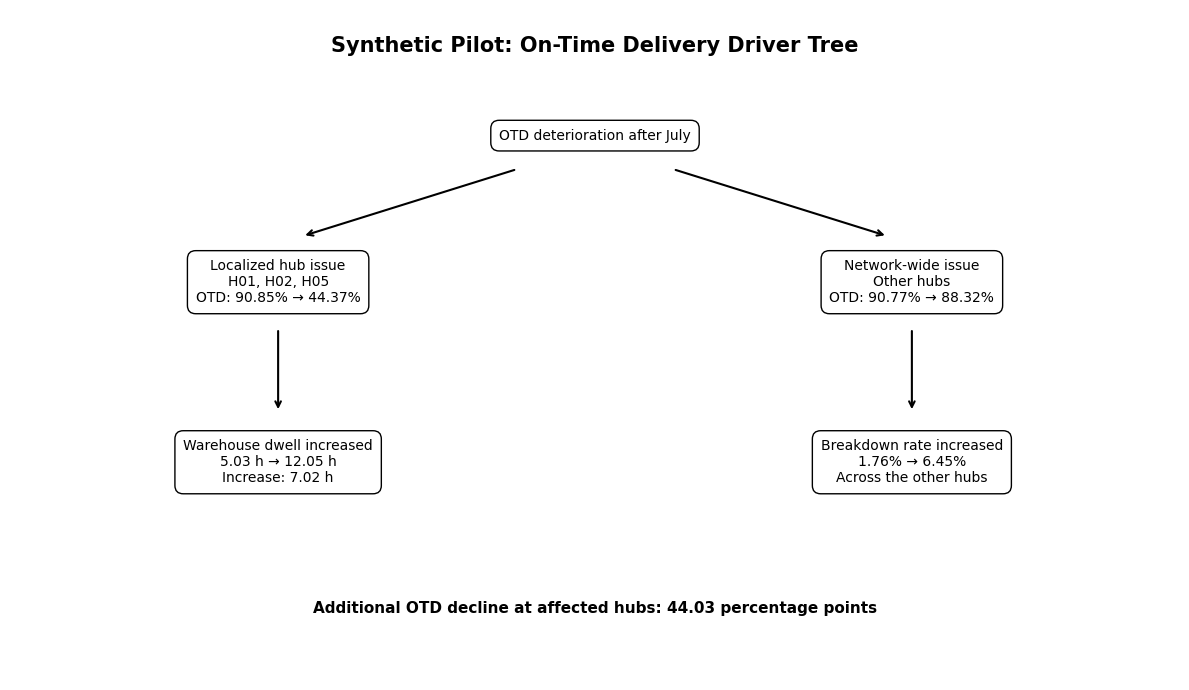

Saved diagram to: /content/drive/MyDrive/Eastern_Freight_Project/outputs/driver_tree/driver_tree_v1.png


In [30]:
import matplotlib.pyplot as plt

# Create the folder for the diagram
TREE_DIR = os.path.join(PROJECT_DIR, "outputs", "driver_tree")
os.makedirs(TREE_DIR, exist_ok=True)

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_xlim(0, 12)
ax.set_ylim(0, 8)
ax.axis("off")

def add_box(x, y, width, height, text):
    ax.text(
        x + width/2, y + height/2, text,
        ha="center", va="center", wrap=True,
        bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="black"),
        fontsize=10
    )

def add_arrow(x1, y1, x2, y2):
    ax.annotate(
        "", xy=(x2, y2), xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )

ax.text(6, 7.5, "Synthetic Pilot: On-Time Delivery Driver Tree",
        ha="center", fontsize=15, weight="bold")

add_box(4.2, 6.1, 3.6, 0.8, "OTD deterioration after July")

add_box(0.5, 4.2, 4.5, 1.1,
        "Localized hub issue\nH01, H02, H05\nOTD: 90.85% → 44.37%")

add_box(7, 4.2, 4.5, 1.1,
        "Network-wide issue\nOther hubs\nOTD: 90.77% → 88.32%")

add_arrow(5.2, 6.1, 3, 5.3)
add_arrow(6.8, 6.1, 9, 5.3)

add_box(0.5, 2.0, 4.5, 1.2,
        "Warehouse dwell increased\n5.03 h → 12.05 h\nIncrease: 7.02 h")

add_box(7, 2.0, 4.5, 1.2,
        "Breakdown rate increased\n1.76% → 6.45%\nAcross the other hubs")

add_arrow(2.75, 4.2, 2.75, 3.2)
add_arrow(9.25, 4.2, 9.25, 3.2)

ax.text(6, 0.8,
        "Additional OTD decline at affected hubs: 44.03 percentage points",
        ha="center", fontsize=11, weight="bold")

plt.tight_layout()

diagram_path = os.path.join(TREE_DIR, "driver_tree_v1.png")
plt.savefig(diagram_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved diagram to:", diagram_path)

In [31]:
monthly_summary = (
    pilot.groupby(pilot["dispatch_date"].dt.month)
    .agg(
        shipments=("on_time_numeric", "size"),
        on_time_rate=("on_time_numeric", "mean")
    )
    .reset_index()
)

monthly_summary["on_time_rate"] *= 100
monthly_summary = monthly_summary.rename(
    columns={"dispatch_date": "month"}
)

print(monthly_summary.round(2).to_string(index=False))

 month  shipments  on_time_rate
     1        777         92.15
     2        699         89.84
     3        801         91.64
     4        753         90.70
     5        758         91.03
     6        762         89.24
     7        756         76.98
     8        796         78.89
     9        755         77.62
    10       1223         76.86
    11       1153         77.45
    12        767         77.57


In [29]:
finding = pd.DataFrame({
    "finding": [
        "Affected hubs OTD decline",
        "Other hubs OTD decline",
        "Additional decline at affected hubs",
        "Affected hubs dwell increase",
        "Other hubs dwell increase"
    ],
    "value": [
        round(affected_decline, 2),
        round(other_decline, 2),
        round(extra_decline, 2),
        12.05 - 5.03,
        5.03 - 5.02
    ],
    "unit": [
        "percentage points",
        "percentage points",
        "percentage points",
        "hours",
        "hours"
    ]
})

finding.to_csv(
    os.path.join(CLEAN_DIR, "key_driver_findings.csv"),
    index=False
)

print(finding.to_string(index=False))
print("Saved key findings.")

                            finding  value              unit
          Affected hubs OTD decline -46.48 percentage points
             Other hubs OTD decline  -2.45 percentage points
Additional decline at affected hubs -44.03 percentage points
       Affected hubs dwell increase   7.02             hours
          Other hubs dwell increase   0.01             hours
Saved key findings.


In [27]:
driver_summary.to_csv(
    os.path.join(CLEAN_DIR, "driver_tree_summary.csv"),
    index=False
)

print("Driver-tree summary saved successfully.")

Driver-tree summary saved successfully.


In [32]:
monthly_by_group = (
    pilot.groupby([
        pilot["dispatch_date"].dt.month.rename("month"),
        "affected_hub"
    ])
    .agg(
        shipments=("on_time_numeric", "size"),
        on_time_rate=("on_time_numeric", "mean")
    )
    .reset_index()
)

monthly_by_group["on_time_rate"] *= 100

monthly_by_group["hub_group"] = monthly_by_group[
    "affected_hub"
].map({
    0: "Other hubs",
    1: "H01, H02 and H05"
})

monthly_by_group = monthly_by_group[
    ["month", "hub_group", "shipments", "on_time_rate"]
]

print(monthly_by_group.round(2).to_string(index=False))

 month        hub_group  shipments  on_time_rate
     1       Other hubs        575         92.35
     1 H01, H02 and H05        202         91.58
     2       Other hubs        516         89.73
     2 H01, H02 and H05        183         90.16
     3       Other hubs        605         92.89
     3 H01, H02 and H05        196         87.76
     4       Other hubs        580         90.52
     4 H01, H02 and H05        173         91.33
     5       Other hubs        574         90.59
     5 H01, H02 and H05        184         92.39
     6       Other hubs        563         88.28
     6 H01, H02 and H05        199         91.96
     7       Other hubs        569         88.22
     7 H01, H02 and H05        187         42.78
     8       Other hubs        608         89.97
     8 H01, H02 and H05        188         43.09
     9       Other hubs        577         87.52
     9 H01, H02 and H05        178         45.51
    10       Other hubs        908         87.56
    10 H01, H02 and 

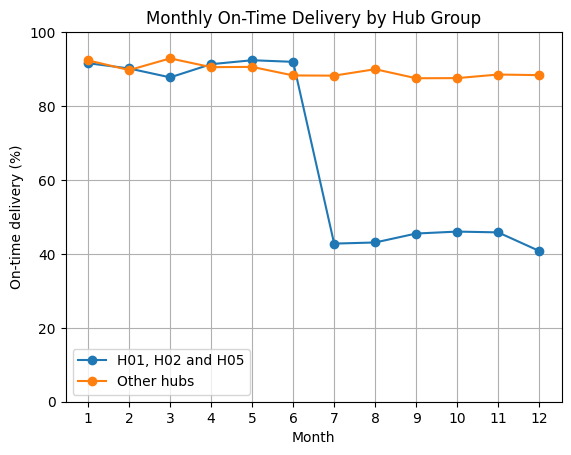

In [33]:
import matplotlib.pyplot as plt

for group_name, group_data in monthly_by_group.groupby("hub_group"):
    plt.plot(
        group_data["month"],
        group_data["on_time_rate"],
        marker="o",
        label=group_name
    )

plt.title("Monthly On-Time Delivery by Hub Group")
plt.xlabel("Month")
plt.ylabel("On-time delivery (%)")
plt.xticks(range(1, 13))
plt.ylim(0, 100)
plt.grid(True)
plt.legend()
plt.show()

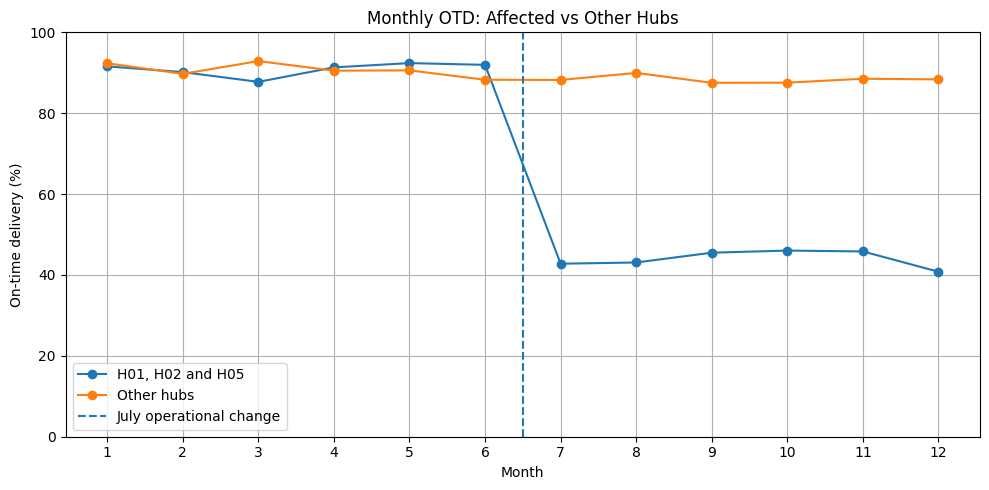

Monthly table and chart saved.


In [34]:
# Create the output folder
CHART_DIR = os.path.join(PROJECT_DIR, "outputs", "charts")
os.makedirs(CHART_DIR, exist_ok=True)

# Save the monthly comparison table
monthly_by_group.to_csv(
    os.path.join(CLEAN_DIR, "monthly_otd_by_hub_group.csv"),
    index=False
)

# Create and save the chart
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

for group_name, group_data in monthly_by_group.groupby("hub_group"):
    ax.plot(
        group_data["month"],
        group_data["on_time_rate"],
        marker="o",
        label=group_name
    )

ax.axvline(6.5, linestyle="--", label="July operational change")
ax.set_title("Monthly OTD: Affected vs Other Hubs")
ax.set_xlabel("Month")
ax.set_ylabel("On-time delivery (%)")
ax.set_xticks(range(1, 13))
ax.set_ylim(0, 100)
ax.grid(True)
ax.legend()
plt.tight_layout()

chart_path = os.path.join(CHART_DIR, "monthly_otd_by_hub_group.png")
plt.savefig(chart_path, dpi=200)
plt.show()

print("Monthly table and chart saved.")

In [35]:
print(pilot.columns.tolist())

['shipment_id', 'hub_id', 'dispatch_date', 'distance_km', 'warehouse_dwell_hours', 'breakdown_flag', 'promised_delivery', 'actual_delivery', 'delivery_delay_hours', 'on_time', 'quarter', 'hub_group', 'period', 'affected_hub', 'post_july', 'on_time_numeric']


In [36]:
# Make sure dispatch_date is a datetime column
pilot["dispatch_date"] = pd.to_datetime(pilot["dispatch_date"])

# Group shipments into weeks, starting Monday
weekly = (
    pilot.set_index("dispatch_date")
    .resample("W-MON")
    .agg(
        shipments=("shipment_id", "count"),
        on_time_rate=("on_time_numeric", "mean"),
        avg_dwell_hours=("warehouse_dwell_hours", "mean"),
        breakdown_rate=("breakdown_flag", "mean")
    )
    .reset_index()
)

# Convert rates into percentages
weekly["on_time_rate"] *= 100
weekly["breakdown_rate"] *= 100

print(weekly.head(10).round(2).to_string(index=False))

dispatch_date  shipments  on_time_rate  avg_dwell_hours  breakdown_rate
   2025-01-06        146         86.99             5.05            2.05
   2025-01-13        176         93.18             5.13            2.27
   2025-01-20        185         95.14             4.63            1.08
   2025-01-27        178         93.82             5.03            0.56
   2025-02-03        149         90.60             5.02            3.36
   2025-02-10        172         90.12             4.98            1.74
   2025-02-17        184         89.13             5.07            2.72
   2025-02-24        176         89.77             5.10            2.27
   2025-03-03        188         90.96             4.82            1.60
   2025-03-10        189         89.42             4.96            2.65


In [37]:
weekly.to_csv(
    os.path.join(CLEAN_DIR, "weekly_operational_metrics.csv"),
    index=False
)

print("Weekly metrics saved successfully.")

Weekly metrics saved successfully.


In [38]:
weekly_grouped = (
    pilot.set_index("dispatch_date")
    .groupby("hub_group")
    .resample("W-MON")
    .agg(
        shipments=("shipment_id", "count"),
        on_time_rate=("on_time_numeric", "mean"),
        avg_dwell_hours=("warehouse_dwell_hours", "mean"),
        breakdown_rate=("breakdown_flag", "mean")
    )
    .reset_index()
)

weekly_grouped["on_time_rate"] *= 100
weekly_grouped["breakdown_rate"] *= 100

# Sort weeks within each hub group
weekly_grouped = weekly_grouped.sort_values(
    ["hub_group", "dispatch_date"]
)

# Calculate rolling four-week averages
for column in ["on_time_rate", "avg_dwell_hours", "breakdown_rate"]:
    weekly_grouped[f"{column}_4wk"] = (
        weekly_grouped.groupby("hub_group")[column]
        .transform(lambda values: values.rolling(4, min_periods=4).mean())
    )

print("Weekly metrics calculated.")

Weekly metrics calculated.


In [39]:
july_window = weekly_grouped[
    (weekly_grouped["dispatch_date"] >= "2025-06-02") &
    (weekly_grouped["dispatch_date"] <= "2025-08-04")
]

columns_to_show = [
    "dispatch_date",
    "hub_group",
    "shipments",
    "on_time_rate",
    "avg_dwell_hours",
    "breakdown_rate",
    "avg_dwell_hours_4wk",
    "breakdown_rate_4wk"
]

print(
    july_window[columns_to_show]
    .round(2)
    .to_string(index=False)
)

dispatch_date     hub_group  shipments  on_time_rate  avg_dwell_hours  breakdown_rate  avg_dwell_hours_4wk  breakdown_rate_4wk
   2025-06-02 Affected hubs         36         86.11             4.93            0.00                 5.09                0.00
   2025-06-09 Affected hubs         41         87.80             5.02            0.00                 5.04                0.00
   2025-06-16 Affected hubs         41         95.12             5.07            0.00                 5.01                0.00
   2025-06-23 Affected hubs         55         94.55             4.96            1.82                 5.00                0.45
   2025-06-30 Affected hubs         51         92.16             5.08            3.92                 5.03                1.43
   2025-07-07 Affected hubs         28         50.00            11.97           10.71                 6.77                4.11
   2025-07-14 Affected hubs         48         45.83            12.16            6.25                 8.54     

In [42]:
# Create simple operational warning flags

weekly_grouped["dwell_alert"] = (
    (weekly_grouped["hub_group"] == "Affected hubs") &
    (weekly_grouped["avg_dwell_hours_4wk"] > 6)
)

weekly_grouped["breakdown_alert"] = (
    weekly_grouped["breakdown_rate_4wk"] > 4
)

# Combine the warning messages
weekly_grouped["warning"] = np.select(
    [
        weekly_grouped["dwell_alert"] & weekly_grouped["breakdown_alert"],
        weekly_grouped["dwell_alert"],
        weekly_grouped["breakdown_alert"]
    ],
    [
        "Dwell and breakdown alert",
        "Warehouse dwell alert",
        "Network breakdown alert"
    ],
    default="No alert"
)

# Inspect the July period
alerts = weekly_grouped[
    (weekly_grouped["dispatch_date"] >= "2025-06-02") &
    (weekly_grouped["dispatch_date"] <= "2025-08-04")
]

print(
    alerts[
        ["dispatch_date", "hub_group",
         "avg_dwell_hours_4wk", "breakdown_rate_4wk", "warning"]
    ].round(2).to_string(index=False)
)

dispatch_date     hub_group  avg_dwell_hours_4wk  breakdown_rate_4wk                   warning
   2025-06-02 Affected hubs                 5.09                0.00                  No alert
   2025-06-09 Affected hubs                 5.04                0.00                  No alert
   2025-06-16 Affected hubs                 5.01                0.00                  No alert
   2025-06-23 Affected hubs                 5.00                0.45                  No alert
   2025-06-30 Affected hubs                 5.03                1.43                  No alert
   2025-07-07 Affected hubs                 6.77                4.11 Dwell and breakdown alert
   2025-07-14 Affected hubs                 8.54                5.68 Dwell and breakdown alert
   2025-07-21 Affected hubs                10.34                5.75 Dwell and breakdown alert
   2025-07-28 Affected hubs                12.13                5.35 Dwell and breakdown alert
   2025-08-04 Affected hubs                12.16  

In [43]:
weekly_grouped.to_csv(
    os.path.join(CLEAN_DIR, "weekly_early_warning_metrics.csv"),
    index=False
)

print("Early-warning metrics saved.")

Early-warning metrics saved.


In [44]:
hypotheses = pd.DataFrame([
    {
        "hypothesis_id": "H01",
        "hypothesis": "Warehouse dwell increased at specific hubs after July",
        "test": "Compare average dwell before and after July by hub group",
        "result": "Affected hubs: 5.03 to 12.05 hours; other hubs: 5.02 to 5.03 hours",
        "status": "Supported in synthetic pilot"
    },
    {
        "hypothesis_id": "H02",
        "hypothesis": "Vehicle breakdowns contributed to lower OTD",
        "test": "Compare OTD for shipments with and without breakdowns",
        "result": "OTD 36.56% with breakdown vs 85.63% without",
        "status": "Strong association in synthetic pilot"
    },
    {
        "hypothesis_id": "H03",
        "hypothesis": "The OTD decline was concentrated in three hubs",
        "test": "Compare monthly OTD by affected and other hub groups",
        "result": "Affected hubs fell to roughly 41-46% from July; other hubs stayed around 87-90%",
        "status": "Supported in synthetic pilot"
    },
    {
        "hypothesis_id": "H04",
        "hypothesis": "Seasonal volume explains the main OTD decline",
        "test": "Compare monthly shipment volumes and OTD by hub group",
        "result": "OTD decline began in July, before the October-November volume increase",
        "status": "Not supported as the main explanation"
    },
    {
        "hypothesis_id": "H05",
        "hypothesis": "Operational metrics provide four weeks of advance warning",
        "test": "Inspect four-week rolling dwell and breakdown metrics before July",
        "result": "Alerts began after OTD deterioration started",
        "status": "Not demonstrated"
    }
])

HYPOTHESIS_DIR = os.path.join(
    PROJECT_DIR, "outputs", "hypothesis_log"
)
os.makedirs(HYPOTHESIS_DIR, exist_ok=True)

hypotheses.to_csv(
    os.path.join(HYPOTHESIS_DIR, "hypothesis_log.csv"),
    index=False
)

print(hypotheses.to_string(index=False))
print("\nHypothesis log saved successfully.")

hypothesis_id                                                hypothesis                                                              test                                                                          result                                status
          H01     Warehouse dwell increased at specific hubs after July          Compare average dwell before and after July by hub group              Affected hubs: 5.03 to 12.05 hours; other hubs: 5.02 to 5.03 hours          Supported in synthetic pilot
          H02               Vehicle breakdowns contributed to lower OTD             Compare OTD for shipments with and without breakdowns                                     OTD 36.56% with breakdown vs 85.63% without Strong association in synthetic pilot
          H03            The OTD decline was concentrated in three hubs              Compare monthly OTD by affected and other hub groups Affected hubs fell to roughly 41-46% from July; other hubs stayed around 87-90%          Suppo

In [45]:
statistical_evidence = pd.DataFrame([
    {
        "test": "Chi-square: OTD vs breakdown",
        "statistic": 707.88,
        "p_value": 5.778266550321827e-156,
        "interpretation": "Strong association between breakdown status and OTD"
    },
    {
        "test": "Chi-square: OTD before vs after July in affected hubs",
        "statistic": 587.88,
        "p_value": 7.236641318830558e-130,
        "interpretation": "Strong difference in OTD before and after July"
    },
    {
        "test": "Welch t-test: dwell before vs after July in affected hubs",
        "statistic": -146.56,
        "p_value": 0.0,
        "interpretation": "Strong difference in average dwell time"
    }
])

statistical_evidence.to_csv(
    os.path.join(HYPOTHESIS_DIR, "statistical_evidence.csv"),
    index=False
)

print(statistical_evidence.to_string(index=False))
print("\nStatistical evidence saved.")

                                                     test  statistic       p_value                                      interpretation
                             Chi-square: OTD vs breakdown     707.88 5.778267e-156 Strong association between breakdown status and OTD
    Chi-square: OTD before vs after July in affected hubs     587.88 7.236641e-130      Strong difference in OTD before and after July
Welch t-test: dwell before vs after July in affected hubs    -146.56  0.000000e+00             Strong difference in average dwell time

Statistical evidence saved.


In [47]:
!pip -q install python-docx

from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.section import WD_SECTION
import os

REPORT_DIR = os.path.join(PROJECT_DIR, "reports")
os.makedirs(REPORT_DIR, exist_ok=True)

doc = Document()

# Page layout
section = doc.sections[0]
section.top_margin = Inches(0.65)
section.bottom_margin = Inches(0.65)
section.left_margin = Inches(0.75)
section.right_margin = Inches(0.75)

styles = doc.styles
styles["Normal"].font.name = "Arial"
styles["Normal"].font.size = Pt(9)

def heading(text, level=1):
    doc.add_heading(text, level=level)

def paragraph(text):
    doc.add_paragraph(text)

# ---------------- PAGE 1 ----------------

title = doc.add_heading(
    "LOGISTICS ROOT-CAUSE ANALYSIS",
    0
)
title.alignment = WD_ALIGN_PARAGRAPH.CENTER

subtitle = doc.add_paragraph(
    "Eastern Freight | Executive Findings Memo"
)
subtitle.alignment = WD_ALIGN_PARAGRAPH.CENTER

p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
r = p.add_run("ILLUSTRATIVE ANALYSIS — SYNTHETIC DATA ONLY")
r.bold = True
r.font.size = Pt(10)

heading("1. Executive summary")

paragraph(
    "This project demonstrates a root-cause analysis of an apparent "
    "on-time delivery (OTD) deterioration across a fictional freight "
    "network of 12 hubs. The analysis uses a synthetic 10,000-shipment "
    "pilot dataset covering 2025. It is not based on actual company "
    "records and must not be presented as verified operational performance."
)

paragraph(
    "In the synthetic pilot, quarterly OTD declined from 91.26% in Q1 "
    "to 77.25% in Q4, a reduction of 14.01 percentage points. The "
    "largest deterioration was concentrated in three hubs: H01, H02 "
    "and H05. Their average warehouse dwell time increased sharply "
    "after July, while the other nine hubs remained comparatively stable."
)

heading("2. Main root-cause findings")

paragraph(
    "Localized warehouse dwell deterioration: In H01, H02 and H05, "
    "OTD fell from 90.85% before July to 44.37% from July onward. "
    "Average warehouse dwell rose from 5.03 to 12.05 hours, an increase "
    "of approximately 7.02 hours. The other nine hubs recorded an OTD "
    "change from 90.77% to 88.32%, while average dwell remained almost "
    "unchanged at approximately 5.02–5.03 hours."
)

paragraph(
    "This comparison suggests that the synthetic OTD deterioration is "
    "primarily localized to the three affected hubs and closely aligned "
    "with an increase in their warehouse dwell time. The additional "
    "decline in the affected group relative to the other hubs was "
    "approximately 44.03 percentage points."
)

paragraph(
    "Network-wide vehicle breakdown association: Shipments with a "
    "recorded breakdown had 36.56% OTD, compared with 85.63% for "
    "shipments without a breakdown. Breakdown incidence increased "
    "after July in both hub groups. This indicates a separate network-wide "
    "risk in the synthetic data, rather than an issue confined to the "
    "three hubs."
)

heading("3. Statistical evidence")

paragraph(
    "The OTD-versus-breakdown chi-square test returned a statistic of "
    "707.88 (p = 5.78 × 10⁻¹⁵⁶). The before/after-July OTD comparison "
    "for affected hubs returned 587.88 (p = 7.24 × 10⁻¹³⁰). A Welch "
    "t-test of dwell time in affected hubs returned t = -146.56 "
    "(p < 0.001; the software displayed 0 due to numerical underflow). "
    "These tests indicate strong statistical differences or associations "
    "within this generated dataset. They do not establish causation."
)

# ---------------- PAGE 2 ----------------

doc.add_page_break()

heading("4. Seasonality assessment")

paragraph(
    "Shipment volume was higher in October and November because the "
    "synthetic data generator deliberately increased shipment weighting "
    "during those months. However, the OTD deterioration began in July, "
    "before this seasonal volume increase. Monthly comparisons show "
    "affected hubs falling to roughly 41–46% OTD from July onward, "
    "while the other hubs generally remained around 87–90%. Therefore, "
    "seasonal volume does not explain the main deterioration in this "
    "pilot scenario."
)

heading("5. Early-warning assessment")

paragraph(
    "A prototype alert rule used four-week rolling average warehouse "
    "dwell above 6 hours and breakdown rate above 4%. In the affected "
    "hubs, these alerts appeared after the OTD decline had already begun. "
    "The analysis therefore does not demonstrate a four-week advance "
    "warning capability. The alert thresholds are exploratory and should "
    "not be deployed without validation against real historical data."
)

heading("6. Recommended operational actions")

actions = [
    "Audit warehouse receiving, staging, sorting and dispatch processes at H01, H02 and H05. Identify where the additional dwell hours accumulate.",
    "Review the July process, staffing, system or facility changes at the three affected hubs. Validate whether a common operational change occurred.",
    "Investigate vehicle maintenance and breakdown reporting across all 12 hubs. Segment breakdowns by vehicle age, route, maintenance history and downtime.",
    "Standardize hub identifiers, scan-event definitions and timestamps. Validate event order, missing scans and local time-zone conversion before calculating operational KPIs.",
    "Build a daily hub-level dashboard for OTD, dwell time, breakdown rate and shipment volume. Back-test candidate alerts to measure actual warning lead time and false-alert rates.",
    "Before implementing changes, repeat the analysis using verified shipment-level records and confirm results with hub operations teams."
]

for item in actions:
    doc.add_paragraph(item, style="List Bullet")

heading("7. Limitations and interpretation")

paragraph(
    "All findings in this memo are based on a synthetic demonstration "
    "dataset created for learning and portfolio development. The "
    "patterns were intentionally introduced to practice analytical "
    "methods. Statistical significance in synthetic data is not evidence "
    "of a real-world operational problem. The analysis is observational; "
    "unmeasured factors and data-generation assumptions may affect "
    "estimated relationships. The logistic regression describes "
    "associations after adjusting for included variables, not causal "
    "effects. The early-warning rule has not demonstrated the requested "
    "four-week lead."
)

heading("Conclusion")

paragraph(
    "The synthetic case demonstrates how shipment, hub, warehouse and "
    "vehicle data can be combined to isolate a localized operational "
    "pattern, distinguish it from network-wide risks and test whether "
    "seasonality is a plausible explanation. The next step in a real "
    "engagement would be to validate these hypotheses using source "
    "systems and operational interviews before recommending or "
    "measuring corrective action."
)

# Save
memo_path = os.path.join(
    REPORT_DIR,
    "Eastern_Freight_Executive_Memo.docx"
)
doc.save(memo_path)

print("Memo saved successfully:")
print(memo_path)

Memo saved successfully:
/content/drive/MyDrive/Eastern_Freight_Project/reports/Eastern_Freight_Executive_Memo.docx


In [48]:
print(os.listdir(REPORT_DIR))
print(os.path.getsize(memo_path), "bytes")

['README.md', 'Eastern_Freight_Executive_Memo.docx']
39143 bytes
